# When Production Regimes Collide
**A birthday-paradox view of AI-assisted manufacturing, on the AI4I 2020 dataset**


In [1]:
import json, math, sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score, roc_auc_score

SEED = 0
ROOT = Path.cwd()                          # start Jupyter from the project folder
OUT = ROOT / "outputs"                     # the only folder this notebook creates
DATA_DIR = ROOT / "data"
OUT.mkdir(exist_ok=True)

# Colours used in the paper figures
RED, BLUE, GREEN, PURPLE, GREY = "#d62728", "#1f77b4", "#2ca02c", "#9467bd", "#7f7f7f"
ORANGE_REC = "#ff7f0e"                     # recorded order (Fig. 4)
BAR_BLUE, BAR_ORANGE, BAR_GREY = "#4c78a8", "#f58518", "#94a3b8"     # bars (Figs. 5, 6) and scatter grey (Fig. 1)

mpl.rcParams.update({
    "font.size": 10, "axes.labelsize": 10.5, "legend.fontsize": 9.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .3, "grid.linewidth": .8, "axes.axisbelow": True,
    "figure.dpi": 110, "pdf.fonttype": 42,
})

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()

KEY, T0 = {}, time.time()
MINUS = "\u2212"
print("output folder:", OUT)

output folder: f:\Projects\when-production-regimes-collide\production-regimes-collisions\outputs


## Data

In [2]:
def load_ai4i():
    local = DATA_DIR / "ai4i2020.csv"
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=601)
        raw = pd.concat([ds.data.features, ds.data.targets], axis=1)
        DATA_DIR.mkdir(exist_ok=True)
        raw.to_csv(local, index=False)                      # keep a copy for offline runs
        return raw, "UCI repository (id 601)"
    except Exception as err:
        print("UCI download not available:", type(err).__name__)
    if local.exists():
        return pd.read_csv(local), "data/ai4i2020.csv"
    raise FileNotFoundError("No internet and no data/ai4i2020.csv. Download the AI4I 2020 CSV and place it in the data folder.")

df, DATA_SOURCE = load_ai4i()
df.columns = [c.strip() for c in df.columns]
print(f"source: {DATA_SOURCE} | shape: {df.shape} | missing values: {int(df.isna().sum().sum())}")

source: UCI repository (id 601) | shape: (10000, 12) | missing values: 0


## Cleaning

In [3]:
fail_col = [c for c in df.columns if c.lower().startswith("machine failure")][0]
ren = {fail_col: "fail"}
for c in df.columns:
    l = c.lower()
    if l == "type": ren[c] = "type"
    elif l.startswith("air"): ren[c] = "air"
    elif l.startswith("process temp"): ren[c] = "proc"
    elif l.startswith("rotational"): ren[c] = "speed"
    elif l.startswith("torque"): ren[c] = "torque"
    elif l.startswith("tool wear"): ren[c] = "wear"
df = df.rename(columns=ren)
if "UDI" in df.columns:
    df = df.sort_values("UDI")
cont = ["air", "proc", "speed", "torque", "wear"]
df = df[["type"] + cont + ["fail"]].reset_index(drop=True)
df["type"] = df["type"].map({"L": 0, "M": 1, "H": 2})
print("rows:", len(df), "| failures:", int(df.fail.sum()), f"({df.fail.mean():.2%})")

rows: 10000 | failures: 339 (3.39%)


## Regime toolkit
A regime is the tuple (product type, five tertile bins), so N = 3 × 3⁵ = 729. Helpers for the Birthday formula, the effective size N_eff, Wilson intervals and the first-collision experiment.

In [4]:
def fit_edges(d, nb=3):
    return {c: np.unique(np.quantile(d[c], np.linspace(0, 1, nb + 1)[1:-1])) for c in cont}

def regimes(d, edges):
    parts = [d["type"].astype(str)] + [pd.Series(np.digitize(d[c], edges[c]), index=d.index).astype(str) for c in cont]
    return parts[0].str.cat(parts[1:], sep="-")

def n_eff(r):
    p = r.value_counts(normalize=True).values
    return 1 / np.sum(p ** 2)

def p_theory(n, N):  return 1 - np.exp(-n * (n - 1) / (2 * N))
def n50_theory(N):   return (1 + np.sqrt(1 + 8 * N * np.log(2))) / 2

def wilson(k, m, z=1.96):
    p = k / m; d = 1 + z * z / m; c = p + z * z / (2 * m)
    a = z * np.sqrt(p * (1 - p) / m + z * z / (4 * m * m))
    return (c - a) / d, (c + a) / d

rng = np.random.default_rng(SEED)          # one stream for Figs. 3, 4 and Table I (order matters for reproducibility)

def first_collision(codes, T=3000, nmax=500):
    out = np.full(T, np.inf)
    for t in range(T):
        s = rng.choice(codes, nmax, replace=False)
        _, i = np.unique(s, return_index=True)
        m = np.ones(nmax, bool); m[i] = False
        if m.any(): out[t] = m.argmax() + 1
    return out

def n50_emp(fc, nmax=500):
    ns = np.arange(5, nmax + 1)
    P = np.array([(fc <= n).mean() for n in ns])
    return float(np.interp(0.5, P, ns)) if P.max() >= .5 else np.nan

NB = 3
N = 3 * NB ** 5
edges_all = fit_edges(df, NB)
reg_all = regimes(df, edges_all)
codes = pd.factorize(reg_all)[0]
Neff = n_eff(reg_all)
vc = reg_all.value_counts()
KEY.update(K=len(vc), singletons=int((vc == 1).sum()), Neff=Neff)
print(f"N={N} | observed={len(vc)} | singletons={(vc == 1).sum()} | largest={vc.iloc[0]} | N_eff={Neff:.0f}")

N=729 | observed=435 | singletons=43 | largest=167 | N_eff=159


## Experiment 1: what does a regime space look like?
Two of the six variables, speed and torque, each cut at its tertiles, give nine cells. The numbers are observations per cell, red points are failures.

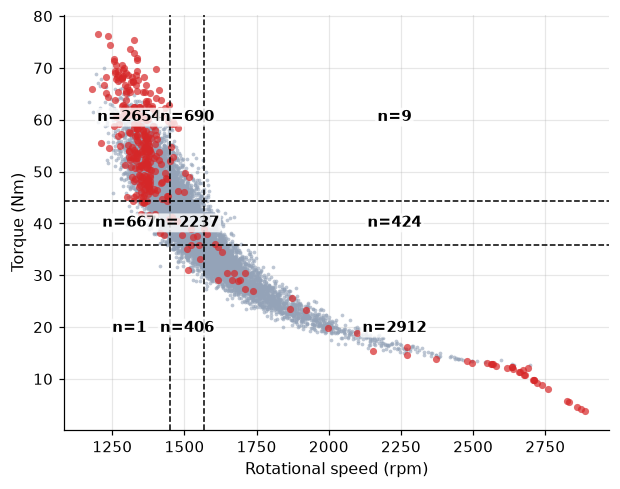

cells add up to 10000


In [5]:
ok = (df.fail == 0).values
fig, ax = plt.subplots(figsize=(6.4, 4.9))
ax.scatter(df.speed[ok], df.torque[ok], s=6, c=BAR_GREY, alpha=.6, linewidths=0, rasterized=True)
ax.scatter(df.speed[~ok], df.torque[~ok], s=22, c=RED, alpha=.7, linewidths=0)

xe = [df.speed.min()] + list(edges_all["speed"]) + [df.speed.max()]
ye = [df.torque.min()] + list(edges_all["torque"]) + [df.torque.max()]
for e in edges_all["speed"]:  ax.axvline(e, c="k", ls="--", lw=1)
for e in edges_all["torque"]: ax.axhline(e, c="k", ls="--", lw=1)
ix, iy = np.digitize(df.speed, edges_all["speed"]), np.digitize(df.torque, edges_all["torque"])
total = 0
for i in range(3):
    for j in range(3):
        c = int(((ix == i) & (iy == j)).sum()); total += c
        ax.text((xe[i] + xe[i + 1]) / 2, (ye[j] + ye[j + 1]) / 2, f"n={c}", ha="center", va="center", fontsize=9.5, fontweight="bold",
                bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.8))
ax.set_xlabel("Rotational speed (rpm)"); ax.set_ylabel("Torque (Nm)")
save_fig(fig, "fig1")
print("cells add up to", total)

## Experiment 2: how fast do collisions arrive in theory?
For N equally likely regimes, P(at least one collision among n observations) = 1 − exp(−n(n−1)/2N). Dots mark the 50% point. No data are used here.

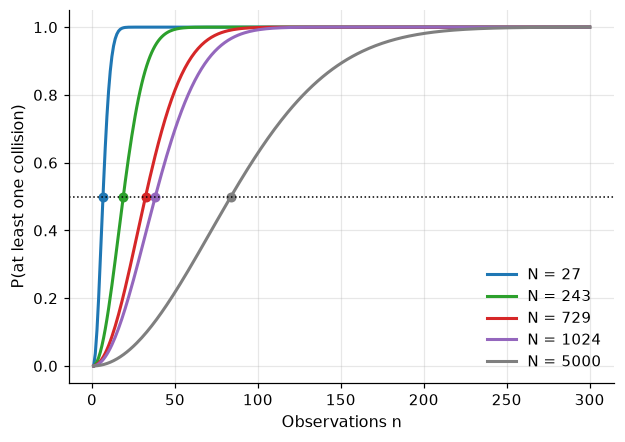

n50 for a uniform N = 729: 32.3


In [6]:
x = np.arange(1, 301)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for Nn, c in zip([27, 243, 729, 1024, 5000], [BLUE, GREEN, RED, PURPLE, GREY]):
    ax.plot(x, p_theory(x, Nn), color=c, lw=2, label=f"N = {Nn}")
    ax.plot(n50_theory(Nn), .5, "o", color=c, ms=5.5)
ax.axhline(.5, c="k", ls=":", lw=1)
ax.set_xlabel("Observations n"); ax.set_ylabel("P(at least one collision)"); ax.legend(loc="lower right")
save_fig(fig, "fig2")
print("n50 for a uniform N = 729:", round(n50_theory(729), 1))

## Experiment 3: does uniform theory hold on production data?
For each n we draw 3,000 random subsamples of the rows (without replacement) and record whether any two share a regime. The empirical curve (95% Wilson intervals) is compared with the uniform benchmark (N = 729) and with the same formula using N_eff.

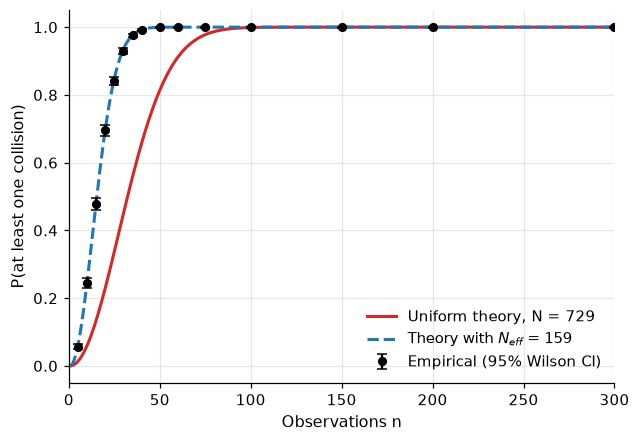

n50 empirical=15.5 | uniform=32.3 | N_eff=15.4
largest gap to uniform=0.50 | largest deviation from N_eff curve=0.012
P(collision) at n=20: empirical 0.69 vs uniform 0.23 | at n=30: 0.93 vs 0.45


In [7]:
T = 3000
fc = first_collision(codes, T)
ns = np.array([5, 10, 15, 20, 25, 30, 35, 40, 50, 60, 75, 100, 150, 200, 300])
emp = np.array([(fc <= n).mean() for n in ns]); lo, hi = wilson(emp * T, T)
xx = np.arange(1, 301)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.plot(xx, p_theory(xx, N), color=RED, lw=2, label=f"Uniform theory, N = {N}")
ax.plot(xx, p_theory(xx, Neff), "--", color=BLUE, lw=2, label=rf"Theory with $N_{{eff}}$ = {Neff:.0f}")
ax.errorbar(ns, emp, yerr=[np.clip(emp - lo, 0, None), np.clip(hi - emp, 0, None)], fmt="o", c="k", capsize=3, ms=5, label="Empirical (95% Wilson CI)")
ax.set_xlim(0, 300); ax.set_xlabel("Observations n"); ax.set_ylabel("P(at least one collision)"); ax.legend(loc="lower right")
save_fig(fig, "fig3")

xg = np.arange(5, 501); Pemp = np.array([(fc <= n).mean() for n in xg])
KEY.update(n50_emp=n50_emp(fc), n50_uniform=n50_theory(N), n50_neff=n50_theory(Neff),
           max_gap=np.abs(Pemp - p_theory(xg, N)).max(), max_dev=np.abs(Pemp - p_theory(xg, Neff)).max(),
           emp20=(fc <= 20).mean(), emp30=(fc <= 30).mean())
print(f"n50 empirical={KEY['n50_emp']:.1f} | uniform={KEY['n50_uniform']:.1f} | N_eff={KEY['n50_neff']:.1f}")
print(f"largest gap to uniform={KEY['max_gap']:.2f} | largest deviation from N_eff curve={KEY['max_dev']:.3f}")
print(f"P(collision) at n=20: empirical {KEY['emp20']:.2f} vs uniform {p_theory(20, N):.2f} | at n=30: {KEY['emp30']:.2f} vs {p_theory(30, N):.2f}")

## Experiment 4: which regimes does the factory actually visit?
Distinct regimes seen as observations accumulate, for random subsamples (30 draws per point, mean ± sd) and for the rows in recorded order, against the uniform benchmarks.

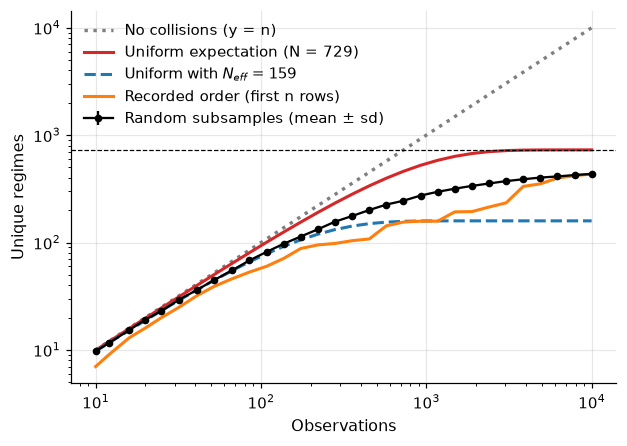

first 1400 rows in order: 180 unique regimes | random subsample: 311


In [8]:
grid = np.unique(np.logspace(1, np.log10(len(df)), 30).astype(int))
draws = [[len(set(rng.choice(codes, n, replace=False))) for _ in range(30)] for n in grid]
rnd_mean, rnd_sd = np.array([np.mean(v) for v in draws]), np.array([np.std(v) for v in draws])
first = np.cumsum(~pd.Series(codes).duplicated().values)                 # distinct regimes in the first n rows
expu = lambda n, M: M * (1 - (1 - 1 / M) ** n)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.plot(grid, grid, ":", color=GREY, lw=2.2, label="No collisions (y = n)")
ax.plot(grid, expu(grid, N), color=RED, lw=2, label=f"Uniform expectation (N = {N})")
ax.plot(grid, expu(grid, Neff), "--", color=BLUE, lw=2, label=rf"Uniform with $N_{{eff}}$ = {Neff:.0f}")
ax.plot(grid, first[grid - 1], color=ORANGE_REC, lw=2, label="Recorded order (first n rows)")
ax.errorbar(grid, rnd_mean, yerr=rnd_sd, fmt="o-", c="k", ms=4, lw=1.5, capsize=0, label="Random subsamples (mean ± sd)")
ax.axhline(N, c="k", ls="--", lw=.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Observations"); ax.set_ylabel("Unique regimes"); ax.legend(loc="upper left")
save_fig(fig, "fig4")

k = 1400
KEY.update(ordered_1400=int(first[k - 1]), random_1400=float(np.mean([len(set(rng.choice(codes, k, replace=False))) for _ in range(100)])))
print(f"first {k} rows in order: {KEY['ordered_1400']} unique regimes | random subsample: {KEY['random_1400']:.0f}")

## Experiment 5: does regime frequency help a model?
Three identical Random Forests (300 trees, balanced class weights, minimum leaf size 2): raw variables (baseline), raw variables plus regime-frequency features (collision-aware), and regime features alone (collision-only). Each split is made first; bin edges and regime counts are then fitted on the training part only. Training rows use a leave-one-out count, test rows use the training count. Ten stratified 70/30 splits (seeds 0–9) and one ordered split. This gives Table III and Fig. 6.

TABLE III (mean ± sd over 10 splits)
                 Baseline Collision-aware Collision-only
Metric                                                 
F1         0.657 ± 0.016   0.647 ± 0.018  0.088 ± 0.008
Precision  0.584 ± 0.025   0.592 ± 0.031  0.049 ± 0.005
Recall     0.751 ± 0.021   0.716 ± 0.027  0.432 ± 0.047
PR-AUC     0.742 ± 0.026   0.716 ± 0.024  0.062 ± 0.009
ROC-AUC    0.967 ± 0.007   0.964 ± 0.007  0.597 ± 0.030
  F1: collision-aware minus baseline -0.0095 ± 0.0181 | better in 2/10 | Wilcoxon p = 0.160
  Precision: collision-aware minus baseline +0.0078 ± 0.0243 | better in 6/10 | Wilcoxon p = 0.557
  Recall: collision-aware minus baseline -0.0353 ± 0.0186 | better in 0/10 | Wilcoxon p = 0.002
  PR-AUC: collision-aware minus baseline -0.0254 ± 0.0251 | better in 1/10 | Wilcoxon p = 0.020
  ROC-AUC: collision-aware minus baseline -0.0031 ± 0.0027 | better in 1/10 | Wilcoxon p = 0.010
ordered split PR-AUC: baseline 0.678 | collision-aware 0.649 | test failures 61


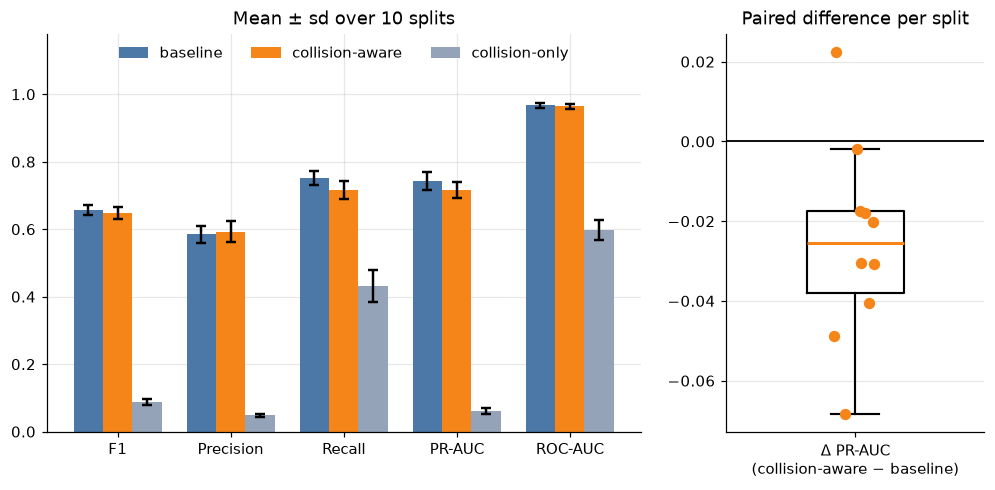

In [9]:
def feats(r_tr, r_te):
    cnt = r_tr.value_counts(); n = len(r_tr)
    Ftr = r_tr.map(cnt).values - 1                       # leave-one-out count for training rows
    Fte = r_te.map(cnt).fillna(0).values                 # training count for test rows, 0 if unseen
    f = lambda F: np.column_stack([F, 1 / (F + 1), -np.log((F + 1) / (n + 1)), (F > 0).astype(int)])
    return f(Ftr), f(Fte), Fte

base = ["type"] + cont

def score(y, pr):
    yh = (pr >= .5).astype(int)
    return dict(F1=f1_score(y, yh), precision=precision_score(y, yh, zero_division=0), recall=recall_score(y, yh),
                PR_AUC=average_precision_score(y, pr), ROC_AUC=roc_auc_score(y, pr))

def fit_pred(A, y, B, seed):
    rf = RandomForestClassifier(300, class_weight="balanced", min_samples_leaf=2, n_jobs=-1, random_state=seed)
    return rf.fit(A, y).predict_proba(B)[:, 1]

def run(nb=3, three=True, seeds=range(10)):
    rows = []
    for s in seeds:
        tr, te = train_test_split(df, test_size=.3, stratify=df.fail, random_state=s)
        e = fit_edges(tr, nb); Ftr, Fte, _ = feats(regimes(tr, e), regimes(te, e))
        sets = {"baseline": (tr[base].values, te[base].values),
                "collision-aware": (np.hstack([tr[base].values, Ftr]), np.hstack([te[base].values, Fte]))}
        if three: sets["collision-only"] = (Ftr, Fte)
        for name, (A, B) in sets.items():
            rows.append(dict(seed=s, model=name, **score(te.fail, fit_pred(A, tr.fail, B, s))))
    return pd.DataFrame(rows)

res = run(3)
mets = ["F1", "precision", "recall", "PR_AUC", "ROC_AUC"]
m, sd = res.groupby("model")[mets].mean(), res.groupby("model")[mets].std()
models = ["baseline", "collision-aware", "collision-only"]
piv = res.pivot(index="seed", columns="model")

# Table III: metrics in rows, models in columns, mean ± sd
lab = {"F1": "F1", "precision": "Precision", "recall": "Recall", "PR_AUC": "PR-AUC", "ROC_AUC": "ROC-AUC"}
t_III = pd.DataFrame({mdl.capitalize(): [f"{m.loc[mdl, k]:.3f} ± {sd.loc[mdl, k]:.3f}" for k in mets] for mdl in models},
                     index=[lab[k] for k in mets])
t_III.index.name = "Metric"
t_III.to_csv(OUT / "table_III.csv", encoding="utf-8-sig")
print("TABLE III (mean ± sd over 10 splits)\n", t_III)

for met in mets:
    d_ = piv[met]["collision-aware"] - piv[met]["baseline"]
    try: p_ = wilcoxon(d_).pvalue
    except ValueError: p_ = np.nan
    print(f"  {lab[met]}: collision-aware minus baseline {d_.mean():+.4f} ± {d_.std():.4f} | better in {(d_ > 0).sum()}/10 | Wilcoxon p = {p_:.3f}")

k = int(.7 * len(df)); tr, te = df.iloc[:k], df.iloc[k:]                     # ordered split: first 70% train, last 30% test
e = fit_edges(tr); Ftr, Fte, _ = feats(regimes(tr, e), regimes(te, e))
pa = average_precision_score(te.fail, fit_pred(tr[base].values, tr.fail, te[base].values, 0))
pb = average_precision_score(te.fail, fit_pred(np.hstack([tr[base].values, Ftr]), tr.fail, np.hstack([te[base].values, Fte]), 0))
KEY.update(ordered_base=pa, ordered_aware=pb, prauc_base=m.loc["baseline", "PR_AUC"], prauc_aware=m.loc["collision-aware", "PR_AUC"])
print(f"ordered split PR-AUC: baseline {pa:.3f} | collision-aware {pb:.3f} | test failures {int(te.fail.sum())}")

# Fig. 6
fig, ax = plt.subplots(1, 2, figsize=(11, 4.7), gridspec_kw=dict(width_ratios=[2.3, 1]))
xs, w = np.arange(len(mets)), .26
for j, (mdl, c) in enumerate(zip(models, [BAR_BLUE, BAR_ORANGE, BAR_GREY])):
    ax[0].bar(xs + (j - 1) * w, m.loc[mdl, mets], w, yerr=sd.loc[mdl, mets], color=c, label=mdl, capsize=3,
              error_kw=dict(lw=1.6, ecolor="k", capthick=1.6))
ax[0].set_xticks(xs); ax[0].set_xticklabels([lab[k_] for k_ in mets]); ax[0].set_ylim(0, 1.18)
ax[0].set_title("Mean ± sd over 10 splits"); ax[0].legend(loc="upper center", ncol=3)

dd = (piv["PR_AUC"]["collision-aware"] - piv["PR_AUC"]["baseline"]).values
ax[1].boxplot(dd, positions=[0], widths=.45, showfliers=False, boxprops=dict(color="k", lw=1.4), whiskerprops=dict(color="k", lw=1.4),
              capprops=dict(color="k", lw=1.4), medianprops=dict(color=BAR_ORANGE, lw=2))
jit = np.random.default_rng(SEED).uniform(-.1, .1, len(dd))               # own generator, leaves `rng` untouched
ax[1].scatter(jit, dd, s=55, color=BAR_ORANGE, zorder=3, linewidths=0)
ax[1].axhline(0, c="k", lw=1.2)
ax[1].set_xlim(-.6, .6); ax[1].set_xticks([0]); ax[1].set_xticklabels(["Δ PR-AUC\n(collision-aware − baseline)"])
ax[1].grid(axis="x", visible=False); ax[1].set_title("Paired difference per split")
save_fig(fig, "fig6")

## Experiment 6: how much does the answer depend on the number of bins?
The regime construction is repeated with 2, 3, 4 and 5 bins per variable. For each we record N, the regimes actually observed, N_eff, the 50% collision point from theory and from 1,000 random subsamples, and the paired PR-AUC change (collision-aware minus baseline). This is Table I.

In [10]:
rows = []
for nb in [2, 3, 4, 5]:
    r = regimes(df, fit_edges(df, nb)); Nn = 3 * nb ** 5; c = pd.factorize(r)[0]
    rr = run(nb, three=False).pivot(index="seed", columns="model")["PR_AUC"]
    dd_ = rr["collision-aware"] - rr["baseline"]
    fcb = first_collision(c, 1000, 600)
    rows.append({"Bins": nb, "N": Nn, "Observed": r.nunique(), "N_eff": round(n_eff(r)),
                 "n50 uniform theory": round(n50_theory(Nn), 1), "n50 empirical": round(n50_emp(fcb, 600), 1),
                 "ΔPR-AUC (better in)": f"{dd_.mean():+.3f}".replace("-", MINUS) + f" ({(dd_ > 0).sum()}/{len(dd_)})"})
t_I = pd.DataFrame(rows)
t_I.to_csv(OUT / "table_I.csv", index=False, encoding="utf-8-sig")
KEY["table_I"] = t_I
print("TABLE I\n", t_I.to_string(index=False))

TABLE I
  Bins    N  Observed  N_eff  n50 uniform theory  n50 empirical ΔPR-AUC (better in)
    2   96        96     29                12.0            6.6       −0.041 (0/10)
    3  729       435    159                32.3           15.7       −0.025 (1/10)
    4 3072      1276    519                65.8           28.9       −0.034 (0/10)
    5 9375      2636   1213               114.5           43.0       −0.032 (0/10)


## Experiment 7: is a rare regime a risky regime?
Each row gets a familiarity score F, the number of times its regime appears in the other folds of a five-fold cross-validation (bin edges refitted on those folds). Rows are grouped by F (unseen, then quartiles of the seen ones). We report the failure rate per group with Wilson intervals, and Spearman's correlation between F and failure. This is Table II and Fig. 5.

TABLE II
 Regime familiarity (training count F)    n  Failures Failure rate (95% CI)
                       Unseen (F = 0)   59         0       0.00% (0.0–6.1)
                          Rare (1–18) 2628        52       1.98% (1.5–2.6)
                    Lower-mid (19–40) 2461        85       3.45% (2.8–4.3)
                    Upper-mid (41–84) 2407        95       3.95% (3.2–4.8)
                         Common (>84) 2445       107       4.38% (3.6–5.3)
Spearman(F, failure): rho = 0.057, p = 1.1e-08


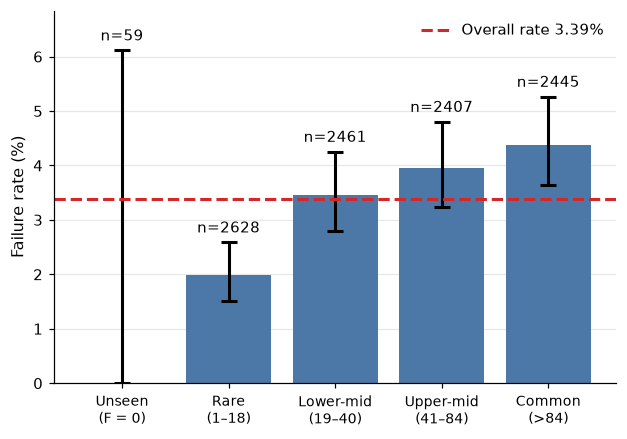

In [11]:
oof = np.zeros(len(df))
for tri, vai in StratifiedKFold(5, shuffle=True, random_state=SEED).split(df, df.fail):
    tr_, va_ = df.iloc[tri], df.iloc[vai]; e = fit_edges(tr_)
    oof[vai] = regimes(va_, e).map(regimes(tr_, e).value_counts()).fillna(0).values

q = np.quantile(oof[oof > 0], [.25, .5, .75]).astype(int)
cuts = [-1, 0, q[0], q[1], q[2], oof.max()]
labs = ["Unseen (F = 0)", f"Rare (1–{q[0]})", f"Lower-mid ({q[0] + 1}–{q[1]})", f"Upper-mid ({q[1] + 1}–{q[2]})", f"Common (>{q[2]})"]
g = pd.cut(oof, cuts, labels=labs); y = df.fail.values; rows = []
for l in labs:
    mk = np.asarray(g == l); k_, n_ = int(y[mk].sum()), int(mk.sum())
    lo_, hi_ = wilson(k_, n_) if n_ else (np.nan, np.nan)
    rows.append(dict(group=l, n=n_, failures=k_, rate=k_ / max(n_, 1), lo=lo_, hi=hi_))
r2 = pd.DataFrame(rows)
t_II = pd.DataFrame({"Regime familiarity (training count F)": r2.group, "n": r2.n, "Failures": r2.failures,
                     "Failure rate (95% CI)": [f"{a * 100:.2f}% ({b * 100:.1f}–{c * 100:.1f})" for a, b, c in zip(r2.rate, r2.lo, r2.hi)]})
t_II.to_csv(OUT / "table_II.csv", index=False, encoding="utf-8-sig")
rho = spearmanr(oof, y)
KEY.update(spearman=rho.statistic, unseen_n=int(r2.n.iloc[0]), overall=y.mean())
print("TABLE II\n", t_II.to_string(index=False))
print(f"Spearman(F, failure): rho = {rho.statistic:.3f}, p = {rho.pvalue:.2g}")

# Fig. 5
lo_err, hi_err = np.clip((r2.rate - r2.lo) * 100, 0, None), np.clip((r2.hi - r2.rate) * 100, 0, None)
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.bar(range(5), r2.rate * 100, width=.8, color=BAR_BLUE, yerr=[lo_err, hi_err], capsize=5, error_kw=dict(lw=2, ecolor="k", capthick=2))
for i, (n_, h_) in enumerate(zip(r2.n, r2.hi)):
    ax.text(i, h_ * 100 + .12, f"n={n_}", ha="center", va="bottom", fontsize=9.5)
ax.axhline(y.mean() * 100, c=RED, ls="--", lw=2, label=f"Overall rate {y.mean():.2%}")
ax.set_xticks(range(5)); ax.set_xticklabels([l.replace(" (", "\n(") for l in labs], fontsize=9)
ax.set_ylim(0, r2.hi.max() * 100 * 1.12); ax.grid(axis="x", visible=False)
ax.set_ylabel("Failure rate (%)"); ax.legend(loc="upper right")
save_fig(fig, "fig5")

## Final Outputs

In [12]:
t1k = KEY["table_I"].set_index("Bins")
checks = [
    ("occupied regimes K", KEY["K"], 435, 0), ("singleton regimes", KEY["singletons"], 43, 0), ("N_eff", round(KEY["Neff"]), 159, 0),
    ("n50 uniform", round(KEY["n50_uniform"], 1), 32.3, .05), ("n50 empirical", round(KEY["n50_emp"], 1), 15.3, .05),
    ("n50 with N_eff", round(KEY["n50_neff"], 1), 15.4, .05),
    ("P(collision) at n=20", round(KEY["emp20"], 2), .69, .006), ("P(collision) at n=30", round(KEY["emp30"], 2), .93, .006),
    ("largest gap to uniform", round(KEY["max_gap"], 2), .51, .006), ("largest deviation from N_eff curve", round(KEY["max_dev"], 3), .011, .0006),
    ("unique regimes after 1,400 rows, recorded order", KEY["ordered_1400"], 178, 0),
    ("unique regimes after 1,400 rows, random", round(KEY["random_1400"]), 312, 1),
    ("PR-AUC baseline, 10 splits", round(KEY["prauc_base"], 3), .755, .0006), ("PR-AUC collision-aware, 10 splits", round(KEY["prauc_aware"], 3), .731, .0006),
    ("ordered split PR-AUC, baseline", round(KEY["ordered_base"], 3), .704, .0006), ("ordered split PR-AUC, collision-aware", round(KEY["ordered_aware"], 3), .685, .0006),
    ("Spearman rho", round(KEY["spearman"], 3), .057, .0006), ("unseen-regime group size", KEY["unseen_n"], 59, 0),
    ("Table I, N_eff (2/3/4/5 bins)", list(t1k["N_eff"]), [29, 159, 519, 1213], 0),
    ("Table I, observed (2/3/4/5 bins)", list(t1k["Observed"]), [96, 435, 1276, 2636], 0),
    ("Table I, n50 empirical (2/3/4/5 bins)", list(t1k["n50 empirical"]), [7.0, 14.4, 27.6, 45.2], .05),
]
for name, got, want, tol in checks:
    same = np.allclose(got, want, atol=tol + 1e-9, rtol=0)
    print(f"{'ok     ' if same else 'differs'} | {name}: got {got}, paper {want}")
print(f"\nfinished in {(time.time() - T0) / 60:.1f} min | files in {OUT.name}/:", ", ".join(sorted(p.name for p in OUT.iterdir())))

ok      | occupied regimes K: got 435, paper 435
ok      | singleton regimes: got 43, paper 43
ok      | N_eff: got 159, paper 159
ok      | n50 uniform: got 32.3, paper 32.3
differs | n50 empirical: got 15.5, paper 15.3
ok      | n50 with N_eff: got 15.4, paper 15.4
differs | P(collision) at n=20: got 0.7, paper 0.69
ok      | P(collision) at n=30: got 0.93, paper 0.93
differs | largest gap to uniform: got 0.5, paper 0.51
differs | largest deviation from N_eff curve: got 0.012, paper 0.011
differs | unique regimes after 1,400 rows, recorded order: got 180, paper 178
ok      | unique regimes after 1,400 rows, random: got 311, paper 312
differs | PR-AUC baseline, 10 splits: got 0.742, paper 0.755
differs | PR-AUC collision-aware, 10 splits: got 0.716, paper 0.731
differs | ordered split PR-AUC, baseline: got 0.678, paper 0.704
differs | ordered split PR-AUC, collision-aware: got 0.649, paper 0.685
ok      | Spearman rho: got 0.057, paper 0.057
ok      | unseen-regime group size: got 59,